# Global CSDA STAC Search
Search one or more collections across a global grid. Completed collection/date/tile slices are checkpointed as GeoJSON and reused when this notebook is run again with the same settings. Failed slices are left for the next run.

The final cell uses the existing `staclib` global acquisition-density map.

In [1]:
from datetime import date
from pathlib import Path
import sys

repo_root = Path.cwd()
if not (repo_root / 'lib').is_dir():
    repo_root = repo_root.parent
sys.path.insert(0, str(repo_root / 'lib'))

import geopandas as gpd
import pandas as pd
import searchlib
import staclib

## Search settings
Edit this cell for another collection, time range, month subset, or region. Use `MONTHS = None` for the full year; otherwise provide month numbers such as `[6, 7, 8]`. Reduce the tile size if individual slices are still too large.

In [30]:
STAC_URL = 'https://csdap.earthdata.nasa.gov/stac'
COLLECTIONS = ['maxar-legion','airbus-optical']
START_DATE = '1999-01-01'
END_DATE = date.today().isoformat()
MONTHS = None  # Example: [6, 7, 8]
BBOX = (-180, -90, 180, 90)
TILE_SIZE_DEGREES = 20
MAX_WORKERS = 20
REQUEST_TIMEOUT_SECONDS = 90
MAX_RETRIES = 2
CHECKPOINT_ROOT = Path.home() / 'csda_stac_cache' / 'global_search'

## Search or resume
The run directory is keyed by the search settings. Completed slices are skipped; unsuccessful slices are reported and will be retried on the next run.

In [31]:
stac_gdf, search_report, checkpoint_run = searchlib.search_global_stac(
    collections=COLLECTIONS,
    start_date=START_DATE,
    end_date=END_DATE,
    checkpoint_dir=CHECKPOINT_ROOT,
    stac_url=STAC_URL,
    bbox=BBOX,
    tile_size_degrees=TILE_SIZE_DEGREES,
    months=MONTHS,
    max_workers=MAX_WORKERS,
    request_timeout=REQUEST_TIMEOUT_SECONDS,
    max_retries=MAX_RETRIES,
)

print(f'Checkpoint run: {checkpoint_run}')
print(f'Unique STAC items loaded: {len(stac_gdf):,}')
print(pd.Series([row['status'] for row in search_report]).value_counts())
failed_slices = [row for row in search_report if row['status'] == 'failed']
if failed_slices:
    display(pd.DataFrame(failed_slices)[['collection', 'period', 'tile_id', 'error']])

Completed 25/9072 slices (0 failed so far)
Completed 50/9072 slices (0 failed so far)
Completed 75/9072 slices (0 failed so far)
Completed 100/9072 slices (0 failed so far)
Completed 125/9072 slices (0 failed so far)
Completed 150/9072 slices (0 failed so far)
Completed 175/9072 slices (0 failed so far)
Completed 200/9072 slices (0 failed so far)
Completed 225/9072 slices (0 failed so far)
Completed 250/9072 slices (0 failed so far)
Completed 275/9072 slices (0 failed so far)
Completed 300/9072 slices (0 failed so far)
Completed 325/9072 slices (0 failed so far)
Completed 350/9072 slices (0 failed so far)
Completed 375/9072 slices (0 failed so far)
Completed 400/9072 slices (0 failed so far)
Completed 425/9072 slices (0 failed so far)
Completed 450/9072 slices (0 failed so far)
Completed 475/9072 slices (0 failed so far)
Completed 500/9072 slices (0 failed so far)
Completed 525/9072 slices (0 failed so far)
Completed 550/9072 slices (0 failed so far)
Completed 575/9072 slices (0 failed

In [23]:
import importlib
importlib.reload(staclib)

<module 'staclib' from '/panfs/ccds02/home/pmontesa/code/csda_summaries/lib/staclib.py'>

## Global item-density heatmap
Each STAC item contributes once, using its footprint centroid for the global grid count.

(<Figure size 1800x900 with 2 Axes>,
 <Axes: title={'center': 'CSDA STAC item density: maxar-legion, airbus-optical (1999-01-01 to 2026-10-01)'}>)

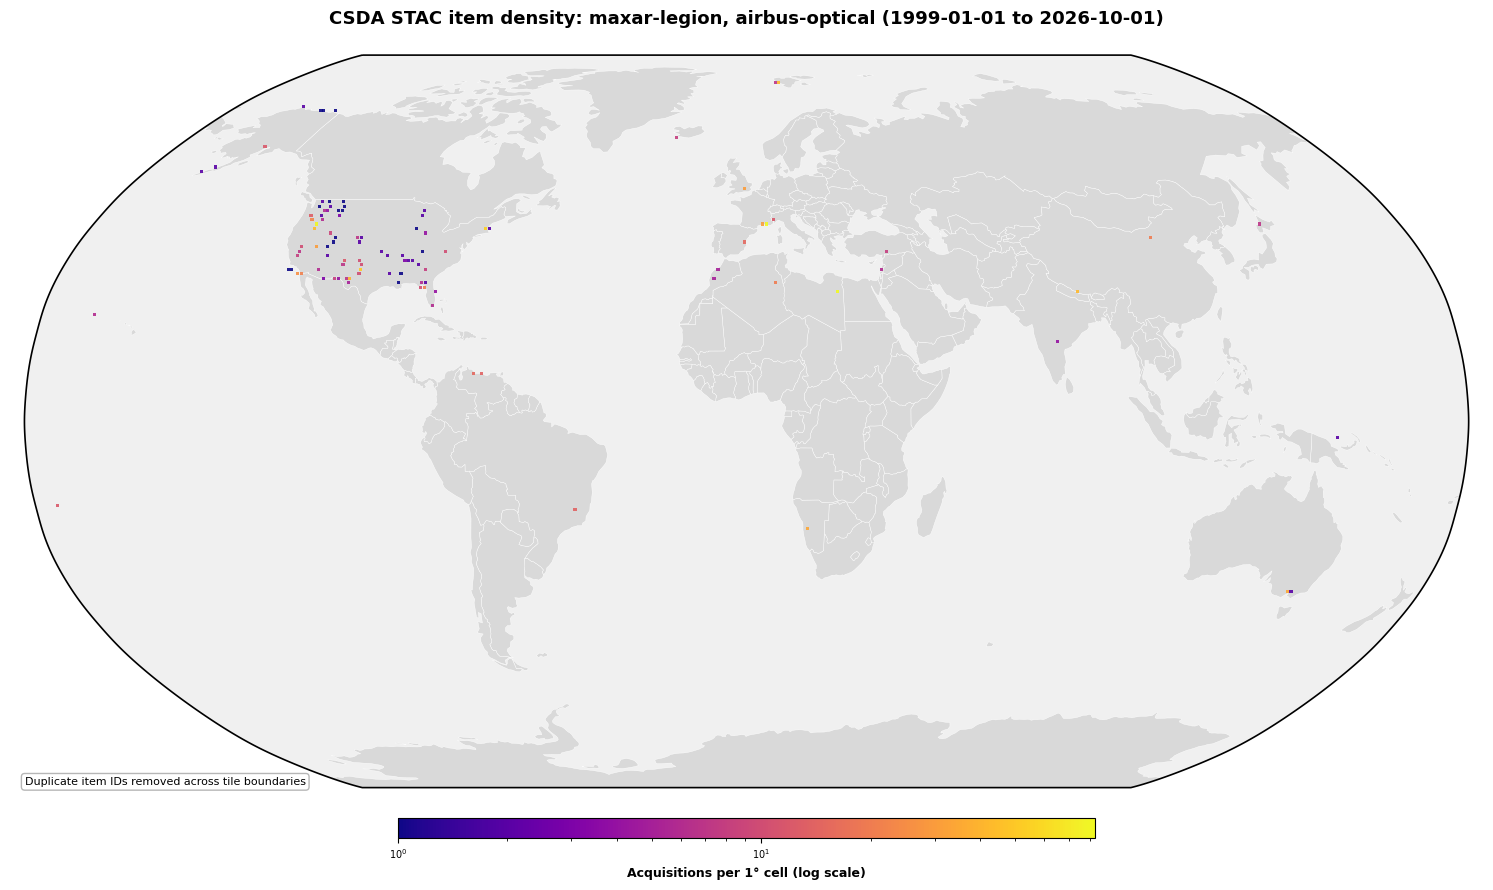

In [32]:
if stac_gdf.empty:
    print('No STAC items are available to plot.')
else:
    fig = staclib.plot_stac_acquisition_density(
        stac_gdf=stac_gdf,
        sites_gdf=None,
        bin_method='grid',
        title=f"CSDA STAC item density: {', '.join(COLLECTIONS)} ({START_DATE} to {END_DATE})",
        filter_text='Duplicate item IDs removed across tile boundaries',
        figsize=(18, 9),
    )
    display(fig)

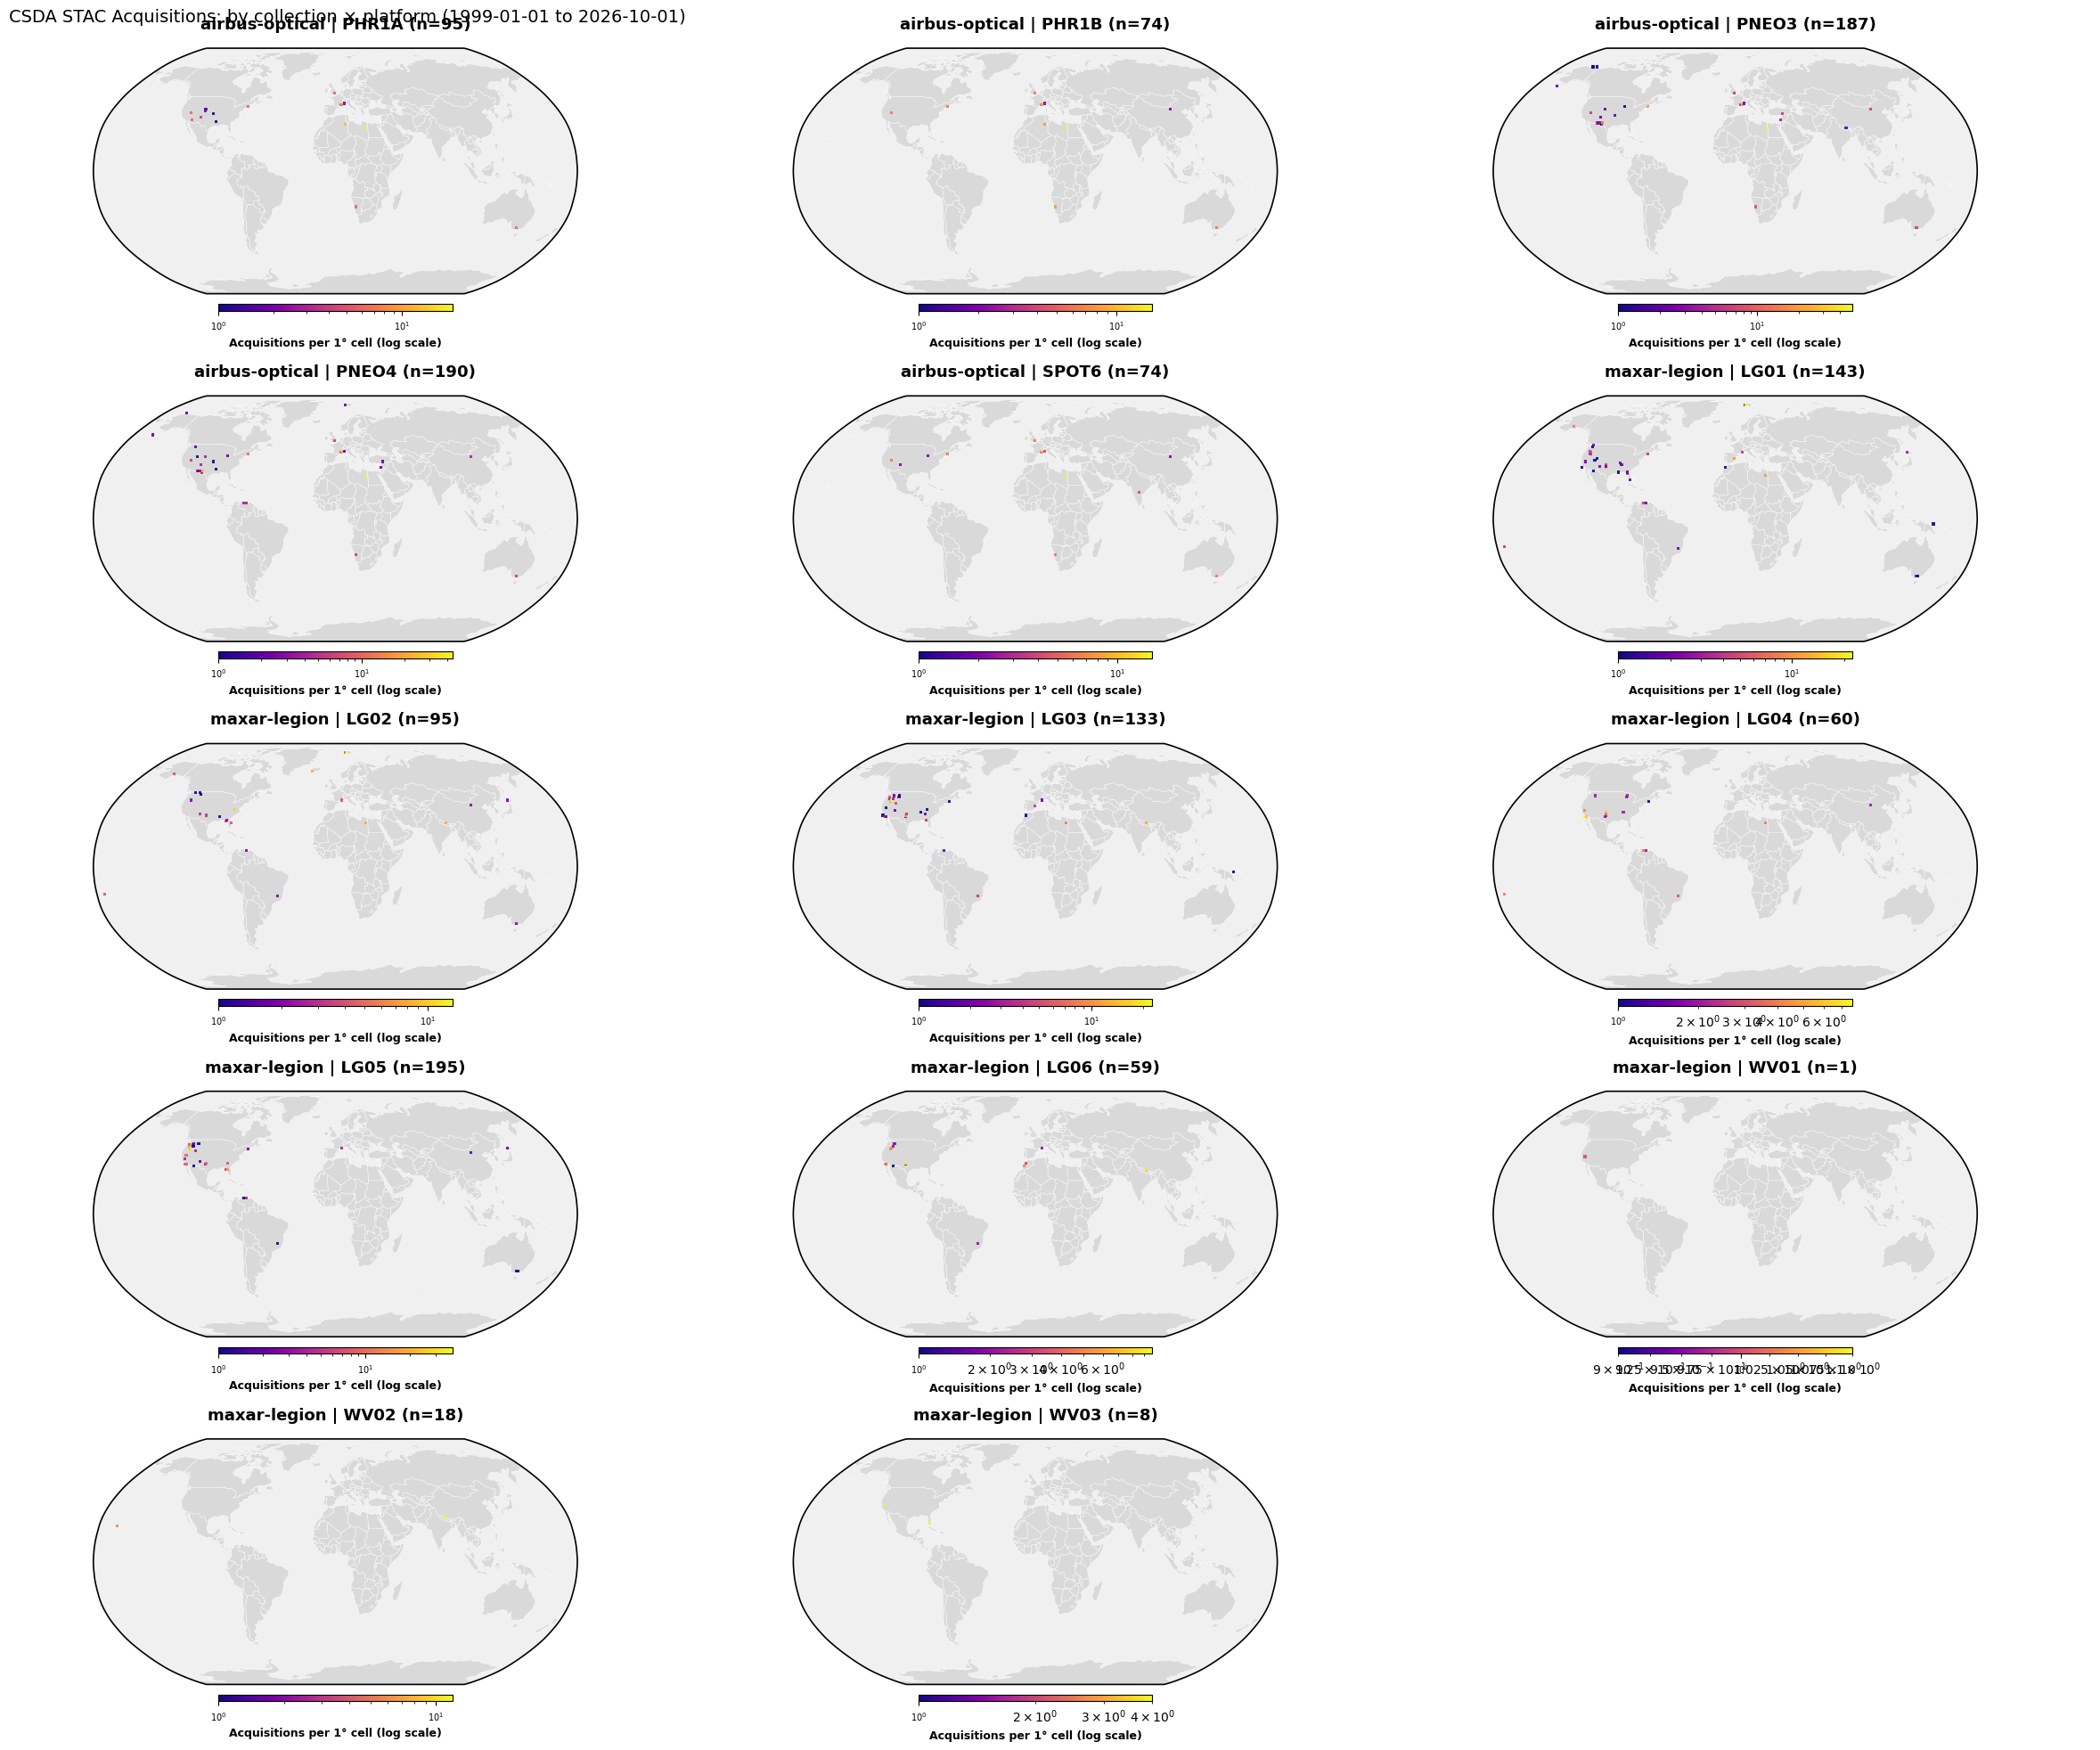

In [35]:
import matplotlib.pyplot as plt

GROUP = ['collection', 'platform']

for c in GROUP:
    if c not in stac_gdf.columns:
        raise KeyError(f"{c!r} not in stac_gdf: {sorted(stac_gdf.columns)[:30]}")

groups = [(k, g) for k, g in stac_gdf.groupby(GROUP, dropna=False) if len(g)]
n = len(groups)
ncols = min(3, n)
nrows = -(-n // ncols)

fig, axes = plt.subplots(nrows, ncols, figsize=(8 * ncols, 4 * nrows),
                         squeeze=False)
flat = axes.ravel()

for ax, ((coll, plat), sub) in zip(flat, groups):
    plt.sca(ax)                          # ← point the pyplot state machine at this ax
    staclib.plot_stac_acquisition_density(
        stac_gdf=sub, sites_gdf=None, bin_method='grid', ax=ax,
        title=f"{coll} | {plat} (n={len(sub):,})", filter_text='')
for ax in flat[n:]:
    ax.axis('off')

fig.suptitle(f"CSDA STAC Acquisitions: by collection × platform "
             f"({START_DATE} to {END_DATE})", x=0.02, ha='left', fontsize=14)
plt.tight_layout()


11 panels (3 groups below 25 items, skipped)
shared vmax = 58


Text(0.01, 0.98, 'CSDA STAC acquisition density by collection × platform (1999-01-01 to 2026-10-01)  •  1,332 items')

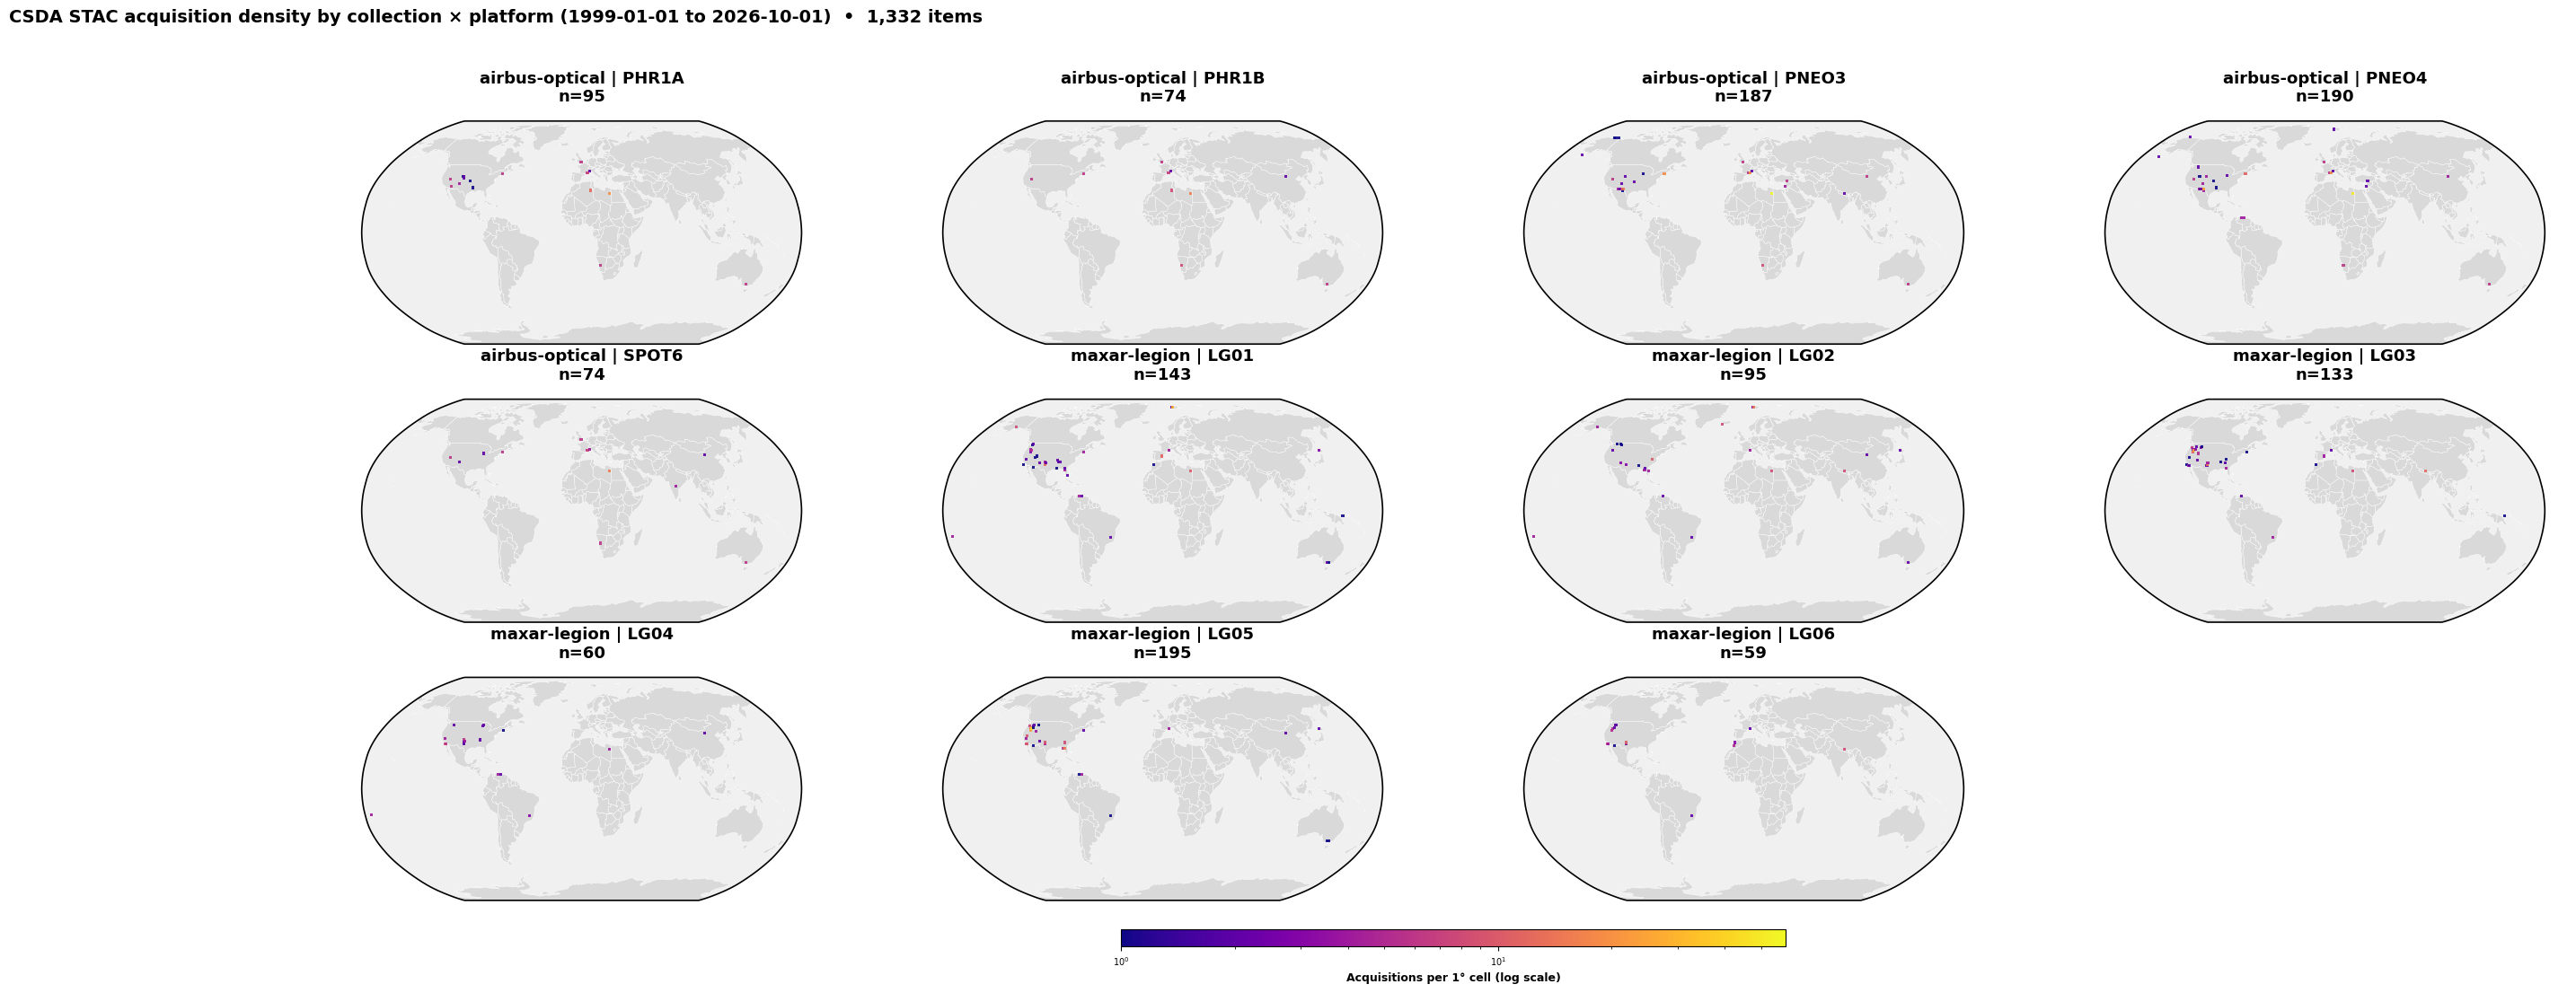

In [36]:
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
import numpy as np

GROUP, NCOLS, MIN_ITEMS, CMAP = ['collection', 'platform'], 4, 25, 'plasma'

plt.close('all')

groups = [(k, g) for k, g in stac_gdf.groupby(GROUP, dropna=False)
          if len(g) >= MIN_ITEMS]
print(f"{len(groups)} panels "
      f"({stac_gdf.groupby(GROUP, dropna=False).ngroups - len(groups)} "
      f"groups below {MIN_ITEMS} items, skipped)")

# shared vmax so panels are directly comparable
VMAX = max(int(np.histogram2d(
            *zip(*[(p.x, p.y) for p in sub.to_crs(4326).geometry.centroid]),
            bins=[np.arange(-180, 181, 1), np.arange(-90, 91, 1)])[0].max())
           for _, sub in groups)
print(f"shared vmax = {VMAX}")

nrows = -(-len(groups) // NCOLS)
fig, axes = plt.subplots(nrows, NCOLS, figsize=(8 * NCOLS, 4.0 * nrows),
                         facecolor='white', squeeze=False)
flat = axes.ravel()

for ax, ((coll, plat), sub) in zip(flat, groups):
    staclib.plot_stac_acquisition_density(
        stac_gdf=sub, sites_gdf=None, bin_method='grid',
        title=f"{coll} | {plat}\nn={len(sub):,}",
        filter_text=None, show_colorbar=False,      # one shared bar instead
        vmax=VMAX, cmap=CMAP, ax=ax)

for ax in flat[len(groups):]:
    ax.axis('off')

sm = plt.cm.ScalarMappable(cmap=CMAP, norm=mcolors.LogNorm(vmin=1, vmax=VMAX))
sm.set_array([])
cbar = fig.colorbar(sm, ax=axes, orientation='horizontal',
                    fraction=0.02, pad=0.03, shrink=0.35, aspect=40)
cbar.set_label('Acquisitions per 1° cell (log scale)', fontweight='bold', fontsize=9)
cbar.ax.tick_params(labelsize=7)

fig.suptitle(f"CSDA STAC acquisition density by collection × platform "
             f"({START_DATE} to {END_DATE})  •  {len(stac_gdf):,} items",
             fontsize=14, fontweight='bold', x=0.01, ha='left')
